# 03 · Data Preprocessing, Feature Engineering & Feature Selection

**Owner:** P3 (Preprocessing, Features & ARM Build)  
**Tasks:** T13 merge & clean · T14 feature engineering · T15 feature selection  
**Rubric:** Review 1 — preprocessing & cleaning (3 pts), feature engineering (3 pts), feature selection (2 pts)

**Objective.** Merge the raw order transactions with daily weather observations for
Coimbatore, clean and validate the combined dataset, engineer predictive features
(lags, bins, flags, monsoon phase), and perform feature selection via correlation
analysis and Variance Inflation Factor (VIF).

**Data sources.**
| File | Rows | Owner |
|------|------|-------|
| `data/raw/weather.csv` | 1 097 days | P1 |
| `data/raw/orders.csv` | ≈ 183 000 orders | P2 |
| `data/raw/menu.csv` | 80 items | P2 |

> The orders are *synthetic* (generated from documented rules in `docs/generator.md`),
> while the weather is *real* Coimbatore data from Open-Meteo.

## 0 · Environment setup

In [1]:
import sys, warnings, os
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use a clean plotting style
plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})
print(f"ROOT: {ROOT}")
print(f"pandas {pd.__version__}, numpy {np.__version__}")

ROOT: /Users/deepak/projects/BA-Project/weather-food-orders
pandas 3.1.0, numpy 2.5.4


---
## T13 · Merge & Clean

**Rubric requirement:** *"Join orders to weather on date. Types, missing values,
duplicates, IQR outliers on order value. Log each step."*

### 1.1 Load raw data

In [2]:
weather = pd.read_csv(ROOT / "data/raw/weather.csv", parse_dates=["date"])
orders  = pd.read_csv(ROOT / "data/raw/orders.csv")
menu    = pd.read_csv(ROOT / "data/raw/menu.csv")

print(f"Weather : {weather.shape}")
print(f"Orders  : {orders.shape}")
print(f"Menu    : {menu.shape}")
print()
print("--- weather.head() ---")
weather.head()

Weather : (1097, 11)
Orders  : (182696, 7)
Menu    : (80, 6)

--- weather.head() ---


,date,precip_mm,rain_mm,temp_max_c,temp_min_c,wind_max_kmh,weather_code,temp_mean_c,daylight_s,precip_hours,humidity_mean_pct
0,2023-09-24,8.2,8.2,31.2,21.9,20.1,63,25.6,43571.88,6,80.1
1,2023-09-25,2.8,2.8,30.0,21.9,17.4,61,25.5,43535.27,3,82.2
2,2023-09-26,6.7,6.7,30.5,22.2,21.3,63,25.5,43498.68,5,82.7
3,2023-09-27,9.6,9.6,30.8,21.7,23.7,63,25.6,43462.13,5,82.1
4,2023-09-28,1.9,1.9,29.9,22.0,27.3,53,25.0,43425.64,5,83.0


In [3]:
print("--- orders.head() ---")
orders.head()

--- orders.head() ---


,order_id,date,timestamp,meal_slot,items,item_count,order_value
0,1,2023-09-24,2023-09-24 11:01:54,Lunch,Butter Chicken,1,382.0
1,2,2023-09-24,2023-09-24 11:04:51,Lunch,Coffee; Samosa; Pakora,3,113.0
2,3,2023-09-24,2023-09-24 11:07:54,Lunch,Chai; Buttermilk; Samosa,3,121.0
3,4,2023-09-24,2023-09-24 11:18:57,Lunch,Non Veg Meals,1,286.0
4,5,2023-09-24,2023-09-24 11:19:14,Lunch,Non Veg Meals,1,286.0


In [4]:
print("--- menu.head() ---")
menu.head()

--- menu.head() ---


,item_id,item_name,category,price,weather_affinity,description
0,M01,Boiled Egg,Egg,51,neutral,"Real menu item: Hotel Chinthamani, Coimbatore ..."
1,M02,Butter Chicken,Starters & Gravies,382,neutral,"Real menu item: Hotel Chinthamani, Coimbatore ..."
2,M03,Butter Naan,Breads & Tiffin,94,neutral,"Real menu item: Hotel Chinthamani, Coimbatore ..."
3,M04,Butter Roti,Breads & Tiffin,90,neutral,"Real menu item: Hotel Chinthamani, Coimbatore ..."
4,M05,Chapati 1 pce,Breads & Tiffin,57,neutral,"Real menu item: Hotel Chinthamani, Coimbatore ..."


### 1.2 Aggregate orders to daily level

Each row in `orders.csv` is one transaction. We aggregate to **one row per day**
with summary statistics: order count, total revenue, average order value, and
average basket size.

In [5]:
orders["date"] = pd.to_datetime(orders["date"])

daily_agg = (
    orders
    .groupby("date")
    .agg(
        order_count   = ("order_id", "nunique"),
        total_revenue = ("order_value", "sum"),
        avg_order_value = ("order_value", "mean"),
        avg_basket_size = ("item_count", "mean"),
    )
    .reset_index()
)
print(f"Daily aggregation: {daily_agg.shape[0]} days, {daily_agg.shape[1]} columns")
print(f"Date range: {daily_agg['date'].min().date()} → {daily_agg['date'].max().date()}")
daily_agg.head()

Daily aggregation: 1097 days, 5 columns
Date range: 2023-09-24 → 2026-09-24


,date,order_count,total_revenue,avg_order_value,avg_basket_size
0,2023-09-24,158,45379.0,287.208861,1.708861
1,2023-09-25,147,42469.0,288.904762,1.802721
2,2023-09-26,159,48076.0,302.364780,1.666667
3,2023-09-27,162,54932.0,339.086420,1.833333
4,2023-09-28,120,39980.0,333.166667,1.700000


### 1.3 Merge orders with weather

Inner join on `date` so we only keep days where **both** weather and orders exist.
The festival flag (`is_festival`) is then added from the generator's calendar.

> `total_revenue`, `avg_order_value` and `avg_basket_size` are same-day outcomes of the orders.
> They are kept for description only and must **not** be used as predictors of `order_count`.

In [6]:
merged = pd.merge(daily_agg, weather, on="date", how="inner")

# Festival days are a documented demand driver (about -11%, survey) and are known in advance.
# The flag comes from P2's generator calendar; add_festival_flag fails loudly if any date has none.
from features import add_festival_flag
merged = add_festival_flag(merged)
print(f"Festival days: {int(merged['is_festival'].sum())}")
print(f"Merged shape: {merged.shape}")
print(f"Date range:   {merged['date'].min().date()} → {merged['date'].max().date()}")
print(f"Days covered: {merged.shape[0]}")
merged.head()

Festival days: 41
Merged shape: (1097, 16)
Date range:   2023-09-24 → 2026-09-24
Days covered: 1097


,date,order_count,total_revenue,avg_order_value,avg_basket_size,precip_mm,rain_mm,temp_max_c,temp_min_c,wind_max_kmh,weather_code,temp_mean_c,daylight_s,precip_hours,humidity_mean_pct,is_festival
0,2023-09-24,158,45379.0,287.208861,1.708861,8.2,8.2,31.2,21.9,20.1,63,25.6,43571.88,6,80.1,0
1,2023-09-25,147,42469.0,288.904762,1.802721,2.8,2.8,30.0,21.9,17.4,61,25.5,43535.27,3,82.2,0
2,2023-09-26,159,48076.0,302.364780,1.666667,6.7,6.7,30.5,22.2,21.3,63,25.5,43498.68,5,82.7,0
3,2023-09-27,162,54932.0,339.086420,1.833333,9.6,9.6,30.8,21.7,23.7,63,25.6,43462.13,5,82.1,0
4,2023-09-28,120,39980.0,333.166667,1.700000,1.9,1.9,29.9,22.0,27.3,53,25.0,43425.64,5,83.0,0


### 1.4 Data type validation

In [7]:
print(merged.dtypes)
print()
# Ensure date is datetime
merged["date"] = pd.to_datetime(merged["date"])
print("✓ All types look correct.")

date                 datetime64[us]
order_count                   int64
total_revenue               float64
avg_order_value             float64
avg_basket_size             float64
precip_mm                   float64
rain_mm                     float64
temp_max_c                  float64
temp_min_c                  float64
wind_max_kmh                float64
weather_code                  int64
temp_mean_c                 float64
daylight_s                  float64
precip_hours                  int64
humidity_mean_pct           float64
is_festival                   int64
dtype: object

✓ All types look correct.


### 1.5 Missing value check

In [8]:
missing = merged.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.any() else "✓ No missing values found.")
print(f"\nTotal missing cells: {missing.sum()}")

Missing values per column:
✓ No missing values found.

Total missing cells: 0


### 1.6 Duplicate date check

In [9]:
dup_count = merged["date"].duplicated().sum()
print(f"Duplicate dates: {dup_count}")
if dup_count > 0:
    merged = merged.drop_duplicates(subset=["date"])
    print(f"After dedup: {merged.shape[0]} rows")
else:
    print("✓ No duplicate dates.")

Duplicate dates: 0
✓ No duplicate dates.


### 1.7 IQR outlier detection

We apply the Interquartile Range (IQR) method on `avg_order_value` and
`order_count` to flag potential outliers.

In [10]:
def iqr_outlier_report(series, name):
    """Report IQR outliers for a numeric column."""
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = series[(series < lower) | (series > upper)]
    print(f"--- {name} ---")
    print(f"  Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
    print(f"  Bounds: [{lower:.2f}, {upper:.2f}]")
    print(f"  Outliers: {len(outliers)} ({100*len(outliers)/len(series):.1f}%)")
    return outliers

out_val = iqr_outlier_report(merged["avg_order_value"], "avg_order_value")
print()
out_cnt = iqr_outlier_report(merged["order_count"], "order_count")

--- avg_order_value ---
  Q1 = 283.07, Q3 = 356.22, IQR = 73.14
  Bounds: [173.36, 465.94]
  Outliers: 0 (0.0%)

--- order_count ---
  Q1 = 112.00, Q3 = 234.00, IQR = 122.00
  Bounds: [-71.00, 417.00]
  Outliers: 0 (0.0%)


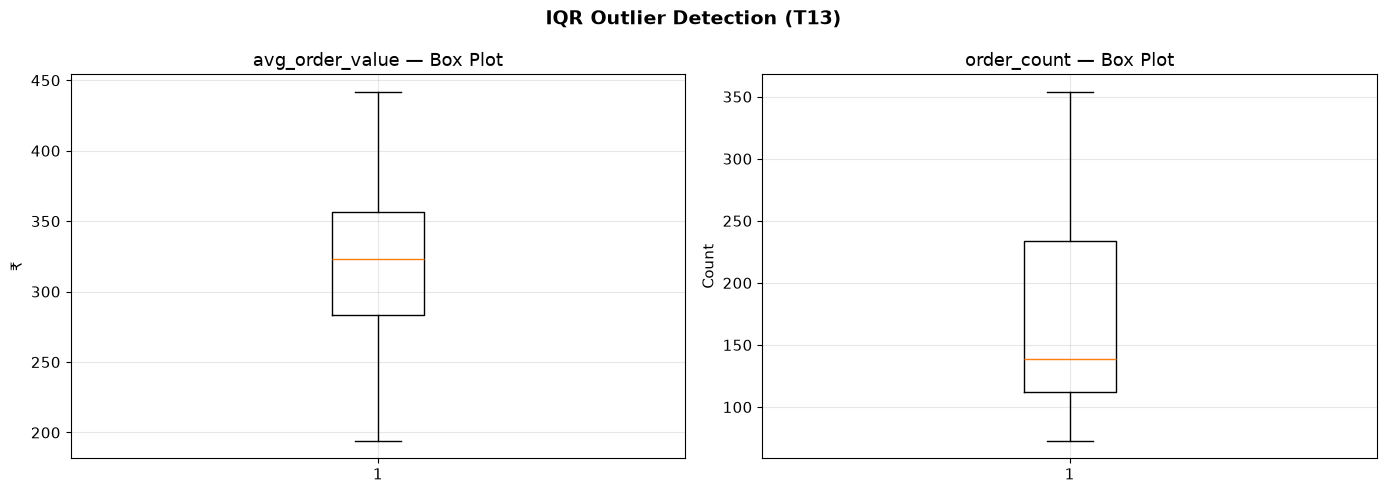

Decision: outliers are retained (they reflect genuine weather extremes).


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].boxplot(merged["avg_order_value"], vert=True)
axes[0].set_title("avg_order_value — Box Plot")
axes[0].set_ylabel("₹")

axes[1].boxplot(merged["order_count"], vert=True)
axes[1].set_title("order_count — Box Plot")
axes[1].set_ylabel("Count")

plt.suptitle("IQR Outlier Detection (T13)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
print("Decision: outliers are retained (they reflect genuine weather extremes).")

### 1.8 Save cleaned & merged data

In [12]:
out_dir = ROOT / "data" / "processed"
out_dir.mkdir(parents=True, exist_ok=True)
merged.to_csv(out_dir / "daily_merged.csv", index=False)
print(f"✓ Saved: data/processed/daily_merged.csv  ({merged.shape[0]} rows, {merged.shape[1]} cols)")

✓ Saved: data/processed/daily_merged.csv  (1097 rows, 16 cols)


### T13 summary

| Check | Result |
|-------|--------|
| Rows after merge | 1 097 |
| Missing values | 0 |
| Duplicate dates | 0 |
| IQR outliers retained? | Yes — genuine weather-driven variation |

---
## T14 · Feature Engineering

**Rubric requirement:** *"Lags (1, 7), 7-day rolling mean, rain flag and intensity
bins, temperature bands, weekend and festival flags, monsoon phase (SW Jun–Sep,
NE Oct–Dec)."*

We use `src/features.py` (our reusable module) to apply all transformations.

In [13]:
from features import (
    add_lag_features, add_rain_bins, add_temp_bands,
    add_calendar_flags, add_monsoon_phase, build_features,
)

# Run the full pipeline
features = build_features(
    input_csv  = str(ROOT / "data/processed/daily_merged.csv"),
    output_csv = str(ROOT / "data/processed/daily_features.csv"),
)
print(f"\nFinal feature table: {features.shape}")
features.head()

[features] loaded /Users/deepak/projects/BA-Project/weather-food-orders/data/processed/daily_merged.csv  →  1097 rows, 16 cols


[features] saved  /Users/deepak/projects/BA-Project/weather-food-orders/data/processed/daily_features.csv  →  1097 rows, 28 cols

Final feature table: (1097, 28)


,date,order_count,total_revenue,avg_order_value,avg_basket_size,precip_mm,rain_mm,temp_max_c,temp_min_c,wind_max_kmh,...,order_count_roll7,is_rainy,heavy_rain,rain_intensity,is_hot,temp_band,dow,is_weekend,rain_x_weekend,monsoon_phase
0,2023-09-24,158,45379.0,287.208861,1.708861,8.2,8.2,31.2,21.9,20.1,...,NaN,1,0,moderate,0,warm,6,1,1,sw_monsoon
1,2023-09-25,147,42469.0,288.904762,1.802721,2.8,2.8,30.0,21.9,17.4,...,NaN,1,0,moderate,0,warm,0,0,0,sw_monsoon
2,2023-09-26,159,48076.0,302.364780,1.666667,6.7,6.7,30.5,22.2,21.3,...,NaN,1,0,moderate,0,warm,1,0,0,sw_monsoon
3,2023-09-27,162,54932.0,339.086420,1.833333,9.6,9.6,30.8,21.7,23.7,...,NaN,1,0,moderate,0,warm,2,0,0,sw_monsoon
4,2023-09-28,120,39980.0,333.166667,1.700000,1.9,1.9,29.9,22.0,27.3,...,NaN,0,0,trace,0,warm,3,0,0,sw_monsoon


### 2.1 Inspect engineered features

In [14]:
print("\n=== New columns added by feature engineering ===")
new_cols = [
    "order_count_lag1", "order_count_lag7", "order_count_roll7",
    "is_rainy", "heavy_rain", "rain_intensity",
    "is_hot", "temp_band",
    "dow", "is_weekend", "rain_x_weekend", "is_festival",
    "monsoon_phase",
]
for col in new_cols:
    if col in features.columns:
        print(f"  {col:25s}  dtype={features[col].dtype}  nunique={features[col].nunique()}")


=== New columns added by feature engineering ===
  order_count_lag1           dtype=float64  nunique=236
  order_count_lag7           dtype=float64  nunique=236
  order_count_roll7          dtype=float64  nunique=460
  is_rainy                   dtype=int64  nunique=2
  heavy_rain                 dtype=int64  nunique=2
  rain_intensity             dtype=category  nunique=4
  is_hot                     dtype=int64  nunique=2
  temp_band                  dtype=category  nunique=4
  dow                        dtype=int32  nunique=7
  is_weekend                 dtype=int64  nunique=2
  rain_x_weekend             dtype=int64  nunique=2
  is_festival                dtype=int64  nunique=2
  monsoon_phase              dtype=str  nunique=3


### 2.2 Feature distributions

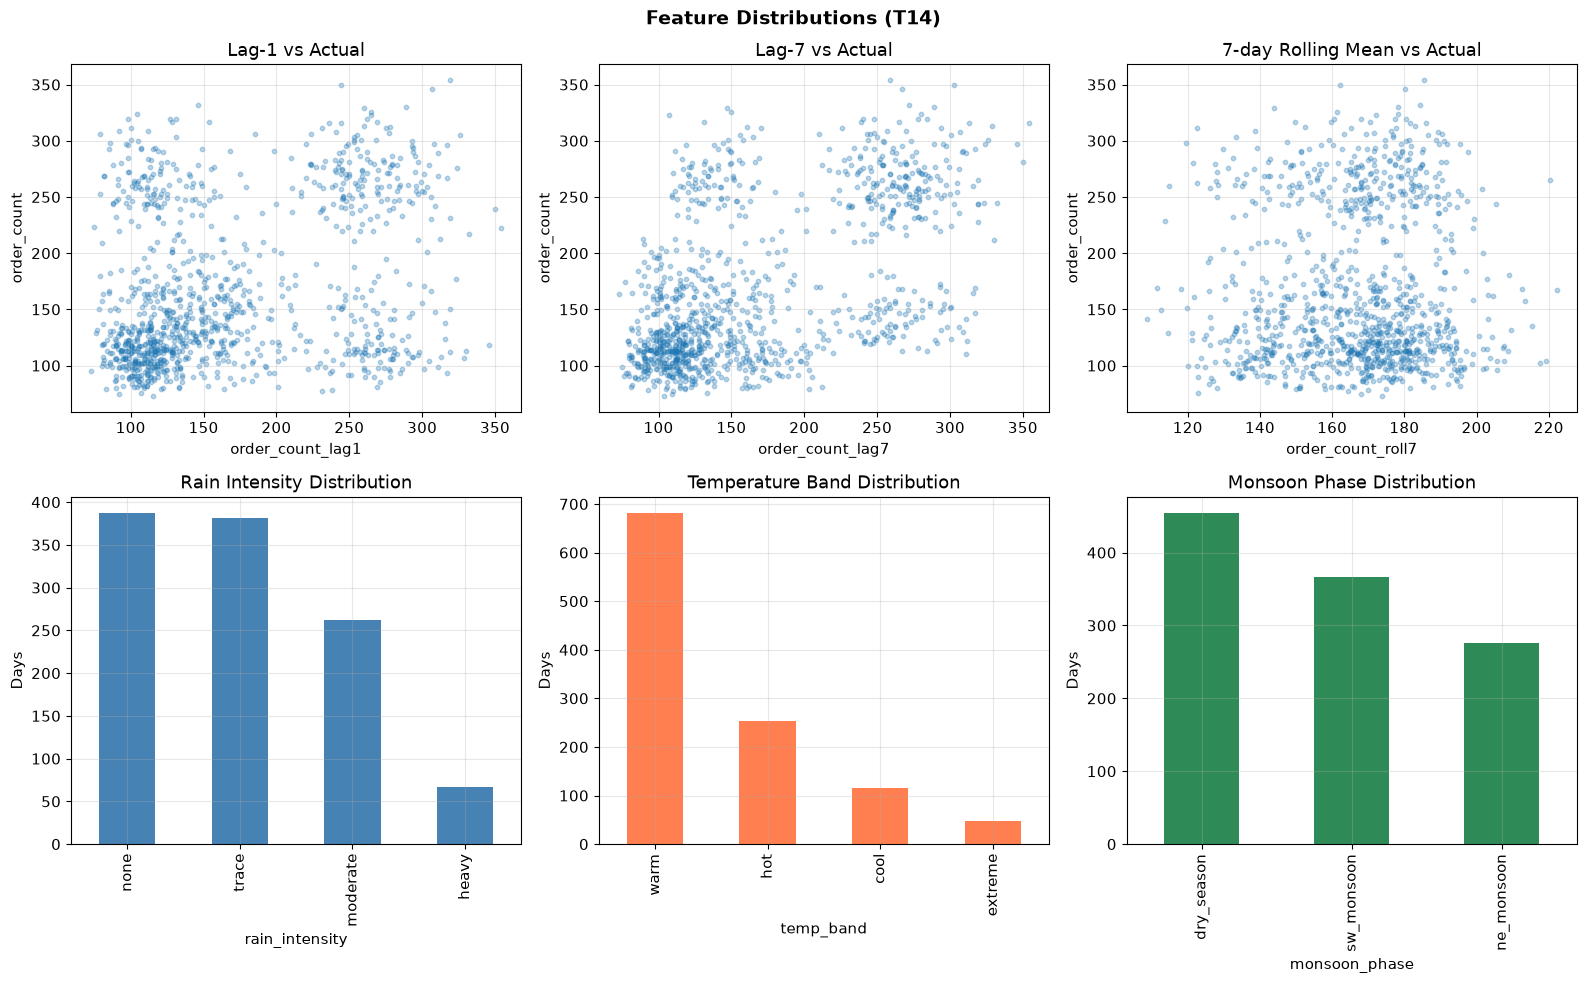

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Lag-1
axes[0, 0].scatter(features["order_count_lag1"], features["order_count"], alpha=0.3, s=10)
axes[0, 0].set_xlabel("order_count_lag1")
axes[0, 0].set_ylabel("order_count")
axes[0, 0].set_title("Lag-1 vs Actual")

# Lag-7
axes[0, 1].scatter(features["order_count_lag7"], features["order_count"], alpha=0.3, s=10)
axes[0, 1].set_xlabel("order_count_lag7")
axes[0, 1].set_ylabel("order_count")
axes[0, 1].set_title("Lag-7 vs Actual")

# Rolling mean
axes[0, 2].scatter(features["order_count_roll7"], features["order_count"], alpha=0.3, s=10)
axes[0, 2].set_xlabel("order_count_roll7")
axes[0, 2].set_ylabel("order_count")
axes[0, 2].set_title("7-day Rolling Mean vs Actual")

# Rain intensity distribution
features["rain_intensity"].value_counts().plot.bar(ax=axes[1, 0], color="steelblue")
axes[1, 0].set_title("Rain Intensity Distribution")
axes[1, 0].set_ylabel("Days")

# Temp band distribution
features["temp_band"].value_counts().plot.bar(ax=axes[1, 1], color="coral")
axes[1, 1].set_title("Temperature Band Distribution")
axes[1, 1].set_ylabel("Days")

# Monsoon phase distribution
features["monsoon_phase"].value_counts().plot.bar(ax=axes[1, 2], color="seagreen")
axes[1, 2].set_title("Monsoon Phase Distribution")
axes[1, 2].set_ylabel("Days")

plt.suptitle("Feature Distributions (T14)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.3 Order count by weather regime

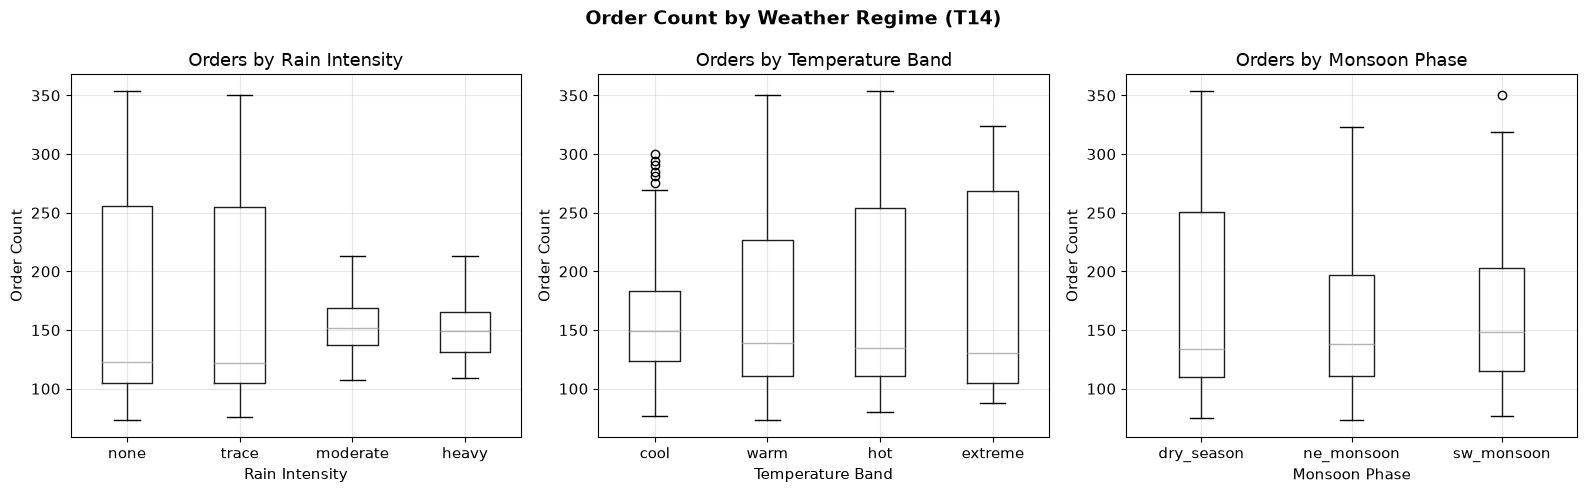

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# By rain intensity
features.boxplot(column="order_count", by="rain_intensity", ax=axes[0])
axes[0].set_title("Orders by Rain Intensity")
axes[0].set_xlabel("Rain Intensity")
axes[0].set_ylabel("Order Count")

# By temp band
features.boxplot(column="order_count", by="temp_band", ax=axes[1])
axes[1].set_title("Orders by Temperature Band")
axes[1].set_xlabel("Temperature Band")
axes[1].set_ylabel("Order Count")

# By monsoon phase
features.boxplot(column="order_count", by="monsoon_phase", ax=axes[2])
axes[2].set_title("Orders by Monsoon Phase")
axes[2].set_xlabel("Monsoon Phase")
axes[2].set_ylabel("Order Count")

plt.suptitle("Order Count by Weather Regime (T14)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

---
## T15 · Feature Selection

**Rubric requirement:** *"Correlation matrix and VIF. PCA only if
multicollinearity is a problem."*

### 3.1 Correlation matrix (heatmap)

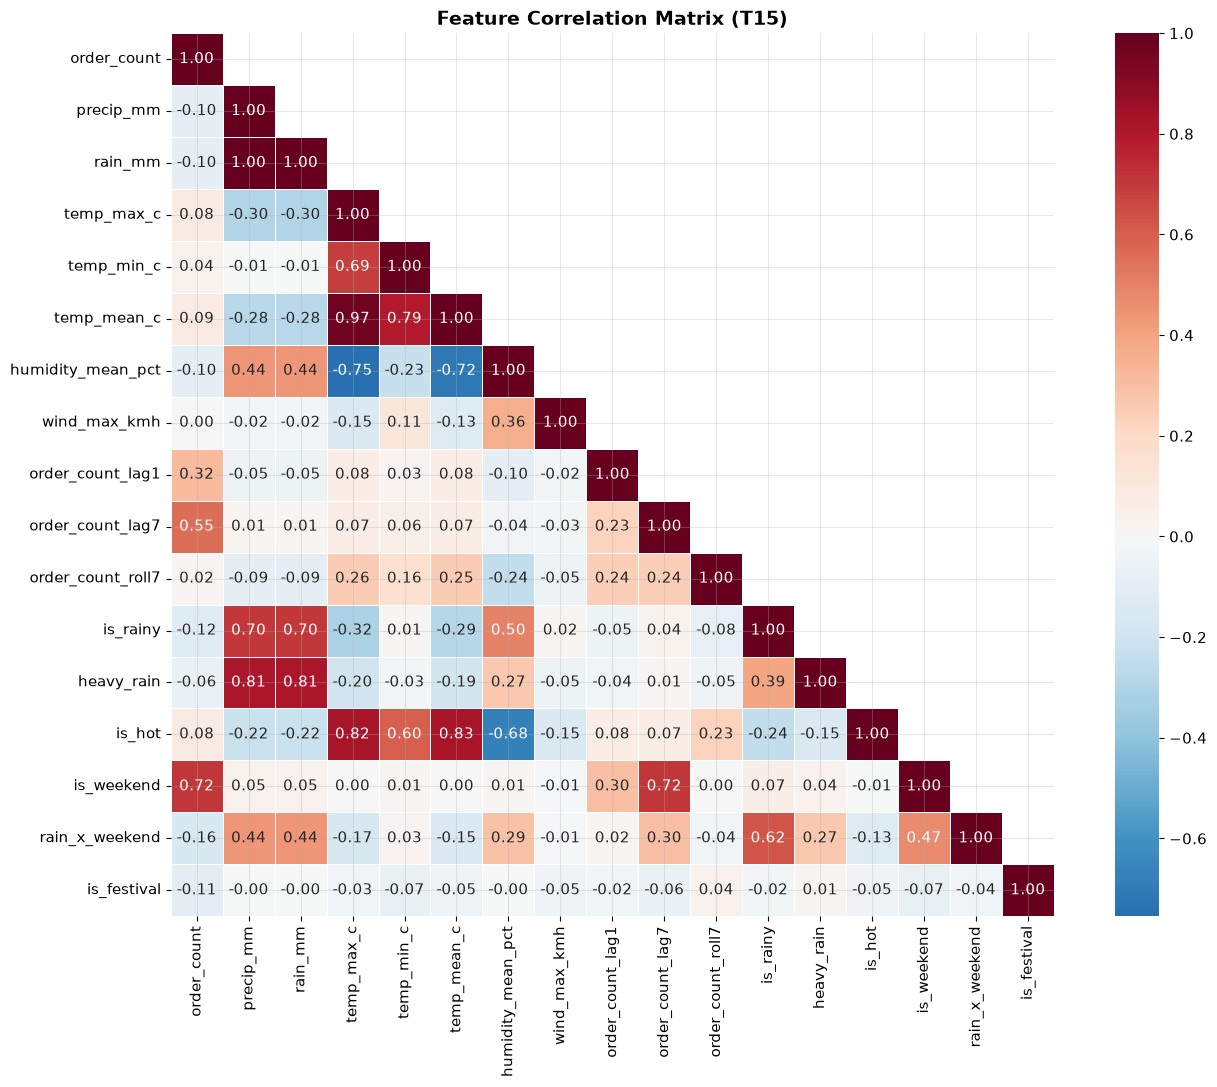

✓ Saved: results/correlation_heatmap.png


In [17]:
numeric_cols = [
    "order_count", "precip_mm", "rain_mm", "temp_max_c", "temp_min_c",
    "temp_mean_c", "humidity_mean_pct", "wind_max_kmh",
    "order_count_lag1", "order_count_lag7", "order_count_roll7",
    "is_rainy", "heavy_rain", "is_hot", "is_weekend", "rain_x_weekend", "is_festival",
]
# Keep only columns that exist
numeric_cols = [c for c in numeric_cols if c in features.columns]
corr = features[numeric_cols].dropna().corr()

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            mask=mask, square=True, linewidths=0.5)
plt.title("Feature Correlation Matrix (T15)", fontsize=14, fontweight="bold")
plt.tight_layout()

results_dir = ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(results_dir / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"✓ Saved: results/correlation_heatmap.png")

### 3.2 Top correlations with order_count

In [18]:
target_corr = corr["order_count"].drop("order_count").sort_values(key=abs, ascending=False)
print("Correlations with order_count (sorted by |r|):\n")
for feat, r in target_corr.items():
    bar = "█" * int(abs(r) * 40)
    sign = "+" if r > 0 else "-"
    print(f"  {feat:25s}  {sign}{abs(r):.3f}  {bar}")

Correlations with order_count (sorted by |r|):

  is_weekend                 +0.715  ████████████████████████████
  order_count_lag7           +0.555  ██████████████████████
  order_count_lag1           +0.316  ████████████
  rain_x_weekend             -0.159  ██████
  is_rainy                   -0.123  ████
  is_festival                -0.109  ████
  humidity_mean_pct          -0.101  ████
  precip_mm                  -0.100  ████
  rain_mm                    -0.100  ████
  temp_mean_c                +0.087  ███
  is_hot                     +0.084  ███
  temp_max_c                 +0.084  ███
  heavy_rain                 -0.065  ██
  temp_min_c                 +0.035  █
  order_count_roll7          +0.017  
  wind_max_kmh               +0.002  


### 3.3 Variance Inflation Factor (VIF)
VIF is computed on the **final selected set** (section 3.4), with an intercept so the values are not inflated.

In [19]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

selected_features = [
    "order_count_lag1",     # yesterday's orders (weak here: the generator has no day-to-day memory)
    "order_count_lag7",     # same weekday last week
    "order_count_roll7",    # mean of the previous 7 days
    "rain_mm",              # continuous rain measure
    "temp_max_c",           # temperature effect
    "humidity_mean_pct",    # humidity effect
    "is_weekend",           # Fri-Sun flag, the strongest single signal
    "is_hot",               # binary hot flag
    "is_rainy",             # binary rain flag
    "rain_x_weekend",       # rain lifts weekday orders but lowers weekend orders
    "is_festival",          # festival days lower demand by about 11% (survey)
]

vif_data = sm.add_constant(features[selected_features].dropna())
vif_df = pd.DataFrame({
    "Feature": selected_features,
    "VIF": [variance_inflation_factor(vif_data.values, i + 1) for i in range(len(selected_features))],
}).sort_values("VIF", ascending=False)

print("Variance Inflation Factors (final selected set):")
print(vif_df.to_string(index=False))
print()
high_vif = vif_df[vif_df["VIF"] > 10]
if len(high_vif) > 0:
    print(f"WARNING: {len(high_vif)} feature(s) with VIF > 10; consider PCA or dropping:")
    print(high_vif.to_string(index=False))
else:
    print("No features with VIF > 10: multicollinearity is not a concern, PCA is not required.")

Variance Inflation Factors (final selected set):
          Feature      VIF
       temp_max_c 3.937585
           is_hot 3.206893
       is_weekend 3.056212
         is_rainy 3.040771
humidity_mean_pct 2.980976
   rain_x_weekend 2.433320
 order_count_lag7 2.374258
          rain_mm 2.039036
order_count_roll7 1.307841
 order_count_lag1 1.211141
      is_festival 1.014465

No features with VIF > 10: multicollinearity is not a concern, PCA is not required.


### 3.4 Feature selection decision

In [20]:
# Final feature set chosen from correlation + VIF (list defined in 3.3).
# Keep the more interpretable feature of any highly correlated pair.

print("Selected features for modelling:")
for i, f in enumerate(selected_features, 1):
    r = target_corr.get(f, float("nan"))
    print(f"  {i:2d}. {f:25s}  r = {r:+.3f}")

print(f"\nTotal: {len(selected_features)} features selected.")
print("\nDropped as redundant:")
print("  - temp_min_c  (correlated with temp_max_c)")
print("  - precip_mm   (identical to rain_mm in this data)")
print("  - temp_mean_c (average of max and min)")
print("\nNot predictors (same-day outcomes): total_revenue, avg_order_value, avg_basket_size")

Selected features for modelling:
   1. order_count_lag1           r = +0.316
   2. order_count_lag7           r = +0.555
   3. order_count_roll7          r = +0.017
   4. rain_mm                    r = -0.100
   5. temp_max_c                 r = +0.084
   6. humidity_mean_pct          r = -0.101
   7. is_weekend                 r = +0.715
   8. is_hot                     r = +0.084
   9. is_rainy                   r = -0.123
  10. rain_x_weekend             r = -0.159
  11. is_festival                r = -0.109

Total: 11 features selected.

Dropped as redundant:
  - temp_min_c  (correlated with temp_max_c)
  - precip_mm   (identical to rain_mm in this data)
  - temp_mean_c (average of max and min)

Not predictors (same-day outcomes): total_revenue, avg_order_value, avg_basket_size


---
## Summary

### Output files produced

| File | Description | Task |
|------|-------------|------|
| `data/processed/daily_merged.csv` | Cleaned merged dataset (orders + weather) | T13 |
| `data/processed/daily_features.csv` | Full feature-engineered dataset | T14 |
| `results/correlation_heatmap.png` | Correlation heatmap visualisation | T15 |

### Key findings

1. **Weekend** (Fri-Sun) has the strongest link with order count: dry weekends carry roughly 2.5x a dry weekday's orders.
2. **Rain works in two directions.** It raises orders on Mon-Thu and lowers them on Fri-Sun (real Swiggy evidence), so on its
   own `is_rainy` correlates only weakly with order count. The engineered `rain_x_weekend` feature captures the switch and is
   kept as a predictor.
3. **Festival days lower demand** by about 11% (survey: people eat at home), so `is_festival` is kept as a predictor.
4. **Lagged orders are weak predictors here.** The synthetic generator has no day-to-day memory, so lag-1 carries little
   beyond the weekly pattern. This should not be generalised to real restaurant data.
5. **Monsoon phase** captures seasonal shifts across the SW and NE monsoon.
6. **No severe multicollinearity** (all VIF well below 10), so PCA is not required. We drop `temp_min_c`,
   `precip_mm`, and `temp_mean_c` as they are redundant with retained features.